# 06 · Client story: figures and key messages for the diocese

This notebook produces the client figures (plain language, no sensor codes, a message in
every title) and builds the PDF report (`report/report.pdf`) from `report/report_template.md`
and the numbers stored by notebooks 01–05 in `report/tables/`.

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd().resolve()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

from src import config as C, load_data as L, results, plotting as P, risk as R, organ as O

P.setup()
df = L.load_processed()
risk = pd.read_parquet(C.RISK_FILE)
risk.index = risk.index.tz_convert(C.LOCAL_TZ)
res = results.load()
summ = R.summarize(risk)

## 1 · Where is the risk? Floor plan in traffic-light colours

Client classification per location, from the share of measured time at *high* risk:
**red ≥ 25 %**, **yellow 10–25 %**, **green < 10 %**. Grey = no data in that period.

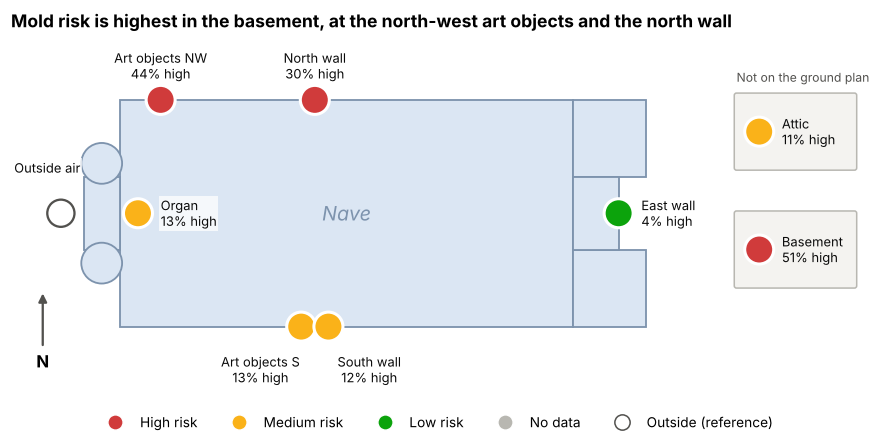

In [2]:
def level_from_share(x):
    if pd.isna(x):
        return np.nan
    return 2 if x >= 0.25 else (1 if x >= 0.10 else 0)

levels = {s: level_from_share(summ.loc[s, "share_high"]) for s in C.INDOOR}
labels = {s: f"{P.name(s)}\n{summ.loc[s, 'share_high']:.0%} high" for s in C.INDOOR}
labels["AU"] = "Outside air"
fig, ax = P.floor_plan(levels, "Mold risk is highest in the basement, at the north-west art objects and the north wall",
                       labels=labels)
P.save(fig, "06_floorplan.png"); plt.show()
results.update(client_levels={P.name(s): (None if pd.isna(v) else int(v)) for s, v in levels.items()})

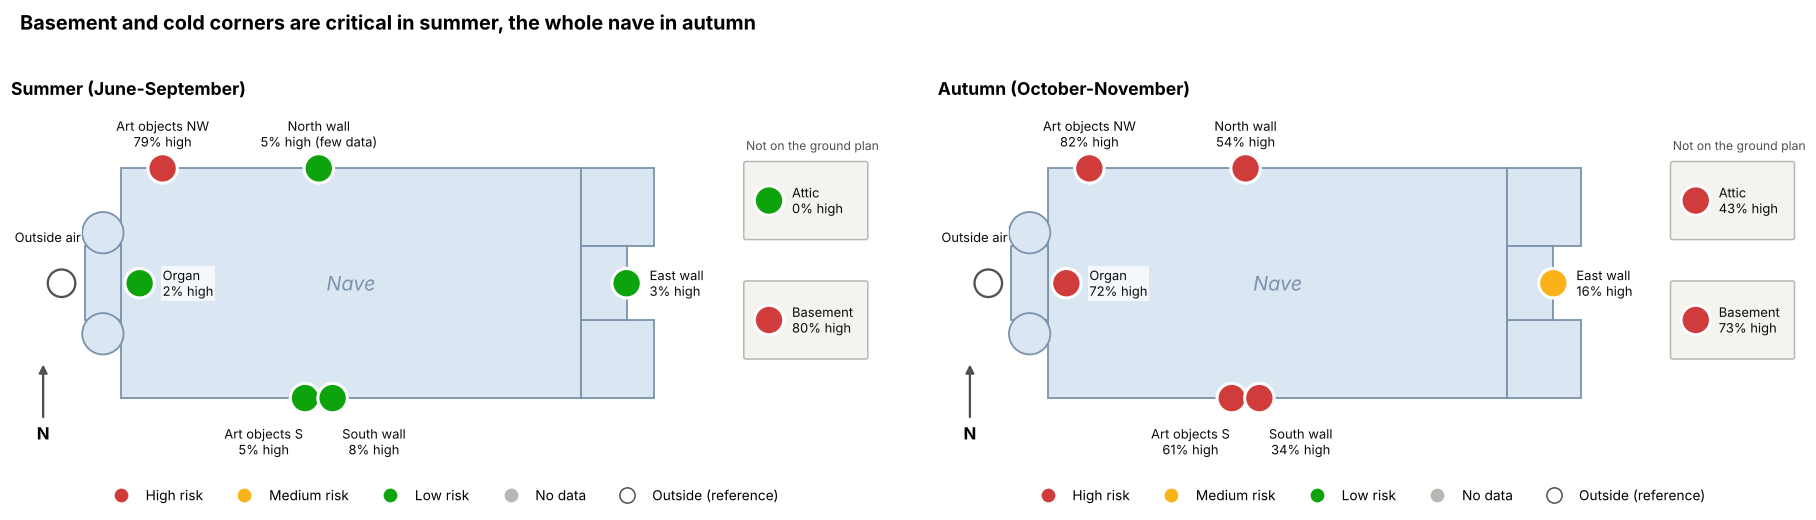

In [3]:
season_share = {}
fig, axes = plt.subplots(1, 2, figsize=(17, 4.9))
for ax, (title, months) in zip(axes, [("Summer (June-September)", [6, 7, 8, 9]), ("Autumn (October-November)", [10, 11])]):
    sub = risk[risk.index.month.isin(months)]
    share = (sub == 2).sum() / sub.notna().sum()
    cover = sub.notna().mean()
    share[sub.notna().sum() < 3 * 24 * 14] = np.nan    # less than two weeks of data -> no data
    season_share["summer" if 6 in months else "autumn"] = {P.name(s): (None if pd.isna(share[s]) else float(share[s])) for s in C.INDOOR}
    lv = {s: level_from_share(share[s]) for s in C.INDOOR}
    lab = {s: P.name(s) + ("\nno data" if pd.isna(share[s]) else
                           f"\n{share[s]:.0%} high" + (" (few data)" if cover[s] < 0.4 else "")) for s in C.INDOOR}
    lab["AU"] = "Outside air"
    P.floor_plan(lv, title, ax=ax, labels=lab)
fig.suptitle("Basement and cold corners are critical in summer, the whole nave in autumn", x=0.02, y=0.99, ha="left",
             fontweight="bold", fontsize=13)
plt.tight_layout()
P.save(fig, "06_floorplan_seasons.png"); plt.show()
results.update(season_share_high=season_share)

In [4]:
# client table (plain names, no codes)
def riskiest_months(s):
    r = risk[s]
    m = (r == 2).groupby(r.index.month).sum() / r.notna().groupby(r.index.month).sum()
    m = m[r.notna().groupby(r.index.month).sum() > 3 * 24 * 14]
    top = m[m >= 0.5].index.tolist()
    names_m = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
    return ", ".join(names_m[i - 1] for i in top) if top else "none above 50 %"

cls = {0: "low (green)", 1: "medium (yellow)", 2: "high (red)"}
order_codes = list(res.get("ranking_codes", C.INDOOR))
client_tab = pd.DataFrame({
    "Location": [C.SENSORS[s]["client"] for s in order_codes],
    "Overall class": [cls[levels[s]] for s in order_codes],
    "Time at high risk": [summ.loc[s, "share_high"] for s in order_codes],
    "Time at medium or high risk": [summ.loc[s, "share_high"] + summ.loc[s, "share_medium"] for s in order_codes],
    "Months with high risk > 50 %": [riskiest_months(s) for s in order_codes],
    "Longest high-risk spell (days)": [summ.loc[s, "longest_high_h"] / 24 for s in order_codes],
    "Data available": [summ.loc[s, "coverage"] for s in order_codes],
})
client_tab["Longest high-risk spell (days)"] = client_tab["Longest high-risk spell (days)"].round(0)
results.save_table(client_tab.set_index("Location"), "client_risk_table")
client_tab

,Location,Overall class,Time at high risk,Time at medium or high risk,Months with high risk > 50 %,Longest high-risk spell (days),Data available
0,Basement storage area,high (red),0.514697,0.620810,"Jun, Jul, Aug, Sep, Oct, Nov",45.0,0.812093
1,"Art objects, north-west corner",high (red),0.440055,0.569350,"May, Jun, Jul, Aug, Sep, Oct, Nov",45.0,0.627473
2,Organ,medium (yellow),0.134661,0.182404,"Oct, Nov",46.0,0.998714
3,North exterior wall (lower level),high (red),0.296892,0.384719,Oct,10.0,0.166241
4,"Art objects, south wall",medium (yellow),0.129957,0.239167,Oct,8.0,0.999980
5,South exterior wall (lower level),medium (yellow),0.119283,0.209011,none above 50 %,9.0,0.538911
6,Attic,medium (yellow),0.109802,0.194003,none above 50 %,7.0,0.969104
7,East exterior wall (lower level),low (green),0.040524,0.125724,none above 50 %,5.0,0.496845


## 2 · When is the risk high? Calendar

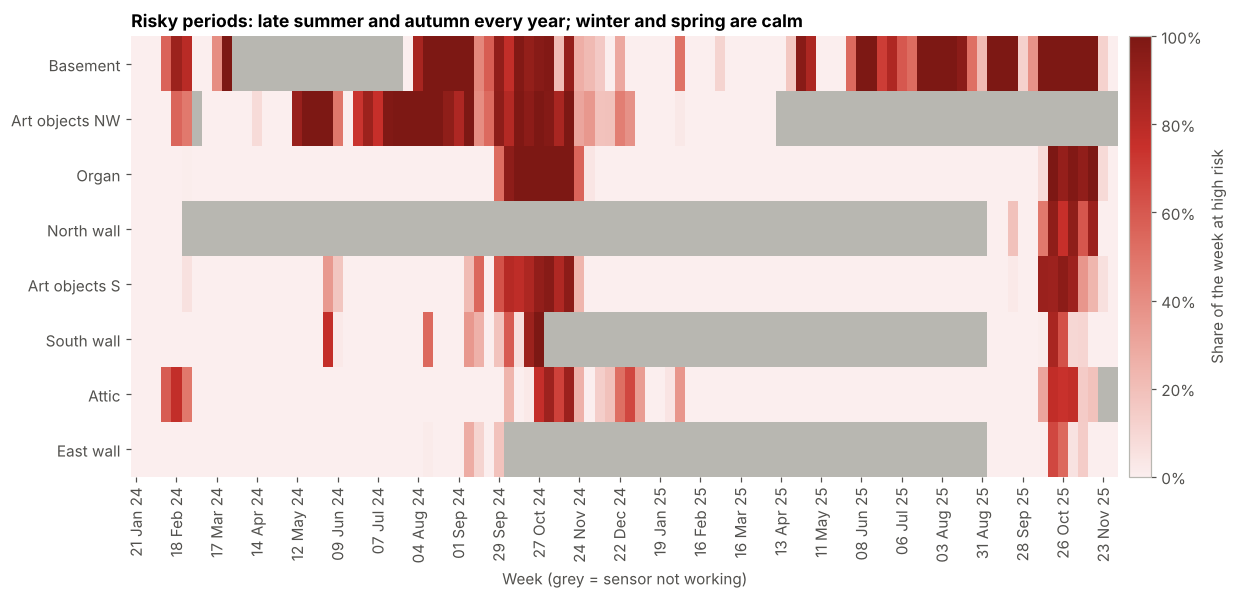

In [5]:
weekly = risk.eq(2).astype(float).where(risk.notna()).resample("W").mean()
weekly[risk.notna().resample("W").mean() < 0.3] = np.nan
weekly.index = weekly.index.strftime("%d %b %y")
order = list(res.get("ranking_codes", C.INDOOR))
fig, ax = P.calendar_heatmap(weekly[order], "Risky periods: late summer and autumn every year; winter and spring are calm",
                             "Share of the week at high risk")
ax.set_xlabel("Week (grey = sensor not working)")
P.save(fig, "06_calendar.png"); plt.show()

## 3 · Organ: when and why does the temperature change too fast?

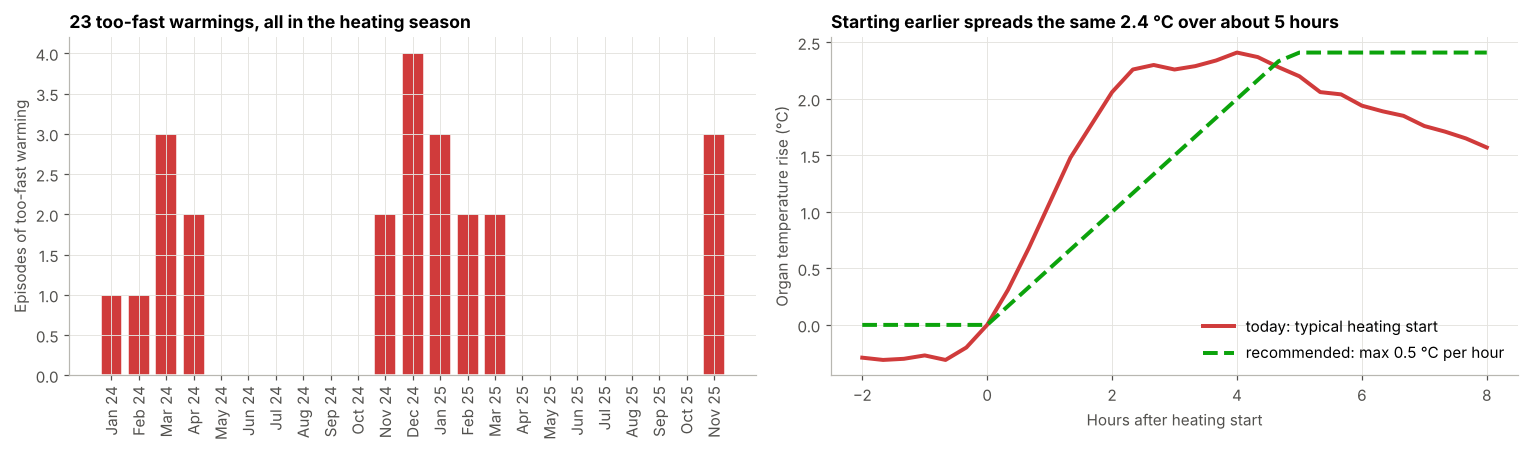

episodes by weekday: {'Friday': 7, 'Saturday': 6, 'Wednesday': 4, 'Tuesday': 2, 'Sunday': 2, 'Thursday': 2}


In [6]:
T = df["temp_O1"]
ev = O.detect_events(T)
eps = O.merge_episodes(ev)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
mon = eps.groupby(eps.start.dt.strftime("%Y-%m")).size()
allm = pd.period_range("2024-01", "2025-11", freq="M").strftime("%Y-%m")
mon = mon.reindex(allm, fill_value=0)
colors = [P.STATUS["high"] if int(m[-2:]) in C.HEATING_MONTHS else P.SERIES[0] for m in mon.index]
axes[0].bar(range(len(mon)), mon.values, color=colors, edgecolor="white")
axes[0].set_xticks(range(len(mon)), [pd.Timestamp(m + "-01").strftime("%b %y") for m in mon.index], rotation=90)
axes[0].set_ylabel("Episodes of too-fast warming")
axes[0].set_title("23 too-fast warmings, all in the heating season")
# typical heating start vs gentle ramp
warm = eps[eps.direction == "warming"]
win = pd.timedelta_range("-2h", "8h", freq="20min")
traj = np.array([T.reindex(t + win).to_numpy() - T.reindex([t]).iloc[0] for t in warm.start])
med = np.nanmedian(traj, axis=0)
hours = win / pd.Timedelta("1h")
rise = np.nanmax(med)
axes[1].plot(hours, med, color=P.STATUS["high"], lw=2.6, label="today: typical heating start")
ramp = np.clip(hours * 0.5, 0, rise)
axes[1].plot(hours, ramp, color=P.STATUS["low"], lw=2.6, ls="--", label="recommended: max 0.5 °C per hour")
axes[1].set_xlabel("Hours after heating start"); axes[1].set_ylabel("Organ temperature rise (°C)")
axes[1].set_title(f"Starting earlier spreads the same {rise:.1f} °C over about {rise / 0.5:.0f} hours")
axes[1].legend(loc="lower right")
plt.tight_layout(); P.save(fig, "06_organ_story.png"); plt.show()
wd = eps.start.dt.day_name().value_counts()
print("episodes by weekday:", wd.to_dict())
results.update(organ_weekday_counts=wd.to_dict(), organ_typical_rise=float(rise))

## 4 · Key messages (for the executive summary)

In [7]:
rank_names = res["ranking_pairwise"]
print("Ranking (fair comparison on shared time):", " > ".join(rank_names))
print("High-risk share per location:", {k: f"{v:.0%}" for k, v in res["share_high"].items()})
print(f"Organ: {res['organ_episodes']} episodes ({res['organ_events']} readings), all warming, in heating seasons;"
      f" typical rise {rise:.1f} °C")
print(f"Data: north wall available {res['availability']['AWn']:.0%} of the time, no wall data in winter 2024/25")

Ranking (fair comparison on shared time): Basement > Art objects NW > Organ > North wall > Art objects S > South wall > Attic > East wall
High-risk share per location: {'Art objects NW': '44%', 'Art objects S': '13%', 'Attic': '11%', 'Basement': '51%', 'East wall': '4%', 'North wall': '30%', 'Organ': '13%', 'South wall': '12%'}
Organ: 23 episodes (74 readings), all warming, in heating seasons; typical rise 2.4 °C
Data: north wall available 17% of the time, no wall data in winter 2024/25


## 5 · Build the PDF report

In [8]:
from src import report
pdf = report.build()
print("report written to", pdf.relative_to(ROOT))

report written to report/report.pdf
